In [1]:
# Floating embodiments on the Jenga design task: a free-floating Allegro hand vs a free-floating Panda gripper.
# Same task (JengaDesign: build the 5x5x5 design from 11 scattered 12x4x4 cm blocks), scoring, block scatter and
# workspace camera; only the embodiment (and its palm camera) differs. Five sections, all in this notebook:
#   1. checks: action spaces, controllers, cameras        4. scripted demonstrations of the demo design (videos)
#   2. random-policy rollouts (videos)                    5. the same scripted solvers on other, random designs
#   3. how reliable the scripted solvers are (7 seeds)
# Run in the ManiSkill .venv on a machine with working Vulkan (CPU physics, GPU rendering).
import numpy as np, torch, matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from api import maniskill, policies, video
from api.jenga_floating_solver import solve_and_record, solve_floating, format_results

EMBODIMENTS = {"allegro hand": "JengaAllegro-v1", "panda gripper": "JengaGripper-v1"}
BASE_LINK = {"JengaAllegro-v1": "base_link", "JengaGripper-v1": "panda_hand"}   # link that tracks the whole hand
FPS = 20                                                                         # the envs' control rate (Hz)

/scratch/pranamlab/farazr/control-proj/control/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# ---- 1. checks: does each embodiment load, hold still, move, and score? ----
def check(env_id, seed=0):
    env = maniskill.make_env(env_id, num_envs=1, render=True, obs_mode="rgbd", sim_backend="physx_cpu")
    obs, _ = env.reset(seed=seed)
    u = env.unwrapped; ag = u.agent; link = ag.robot.links_map[BASE_LINK[env_id]]
    zero = torch.zeros(env.action_space.shape)
    out = {"action dims": env.action_space.shape[0], "control mode": u.control_mode,
           "active joints": len(ag.robot.get_active_joints()),
           "cameras": {k: tuple(d["rgb"].shape[1:3]) for k, d in obs["sensor_data"].items()}}
    p0 = link.pose.p[0].clone()
    for _ in range(100): env.step(zero)
    out["hover drift (m)"] = round((link.pose.p[0] - p0).norm().item(), 5)
    q = link.pose.p[0].clone(); a = zero.clone(); a[0] = 1.0                     # +x on the root
    for _ in range(20): env.step(a)
    out["+x move over 20 steps (m, target 0.4)"] = round((link.pose.p[0] - q)[0].item(), 3)
    obs, _ = env.reset(seed=seed)
    u.place_design()                                                              # teleport blocks into the design
    for _ in range(60): obs, r, term, trunc, info = env.step(zero)
    out["score after place_design"] = f"{info['score'].item()} / {info['max_score'].item()}"
    obs, _ = env.reset(seed=seed + 1)
    a = zero.clone(); a[2] = -1.0                                                 # lower the embodiment ~8 cm
    for _ in range(4): obs, *_ = env.step(a)
    cams = {k: obs["sensor_data"][k]["rgb"][0].cpu().numpy() for k in ("base_camera", "palm_camera")}
    env.close()
    return out, cams

results, frames = {}, {}
for name, env_id in EMBODIMENTS.items():
    results[name], frames[name] = check(env_id)
    print(f"--- {name} ({env_id})")
    for k, v in results[name].items(): print(f"  {k}: {v}")

--- allegro hand (JengaAllegro-v1)
  action dims: 22
  control mode: pd_joint_delta_pos
  active joints: 22
  cameras: {'base_camera': (128, 128), 'palm_camera': (128, 128)}
  hover drift (m): 0.0
  +x move over 20 steps (m, target 0.4): 0.37
  score after place_design: 33 / 33


2026-10-11 18:38:23,027 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


--- panda gripper (JengaGripper-v1)
  action dims: 7
  control mode: pd_joint_delta_pos
  active joints: 8
  cameras: {'base_camera': (128, 128), 'palm_camera': (128, 128)}
  hover drift (m): 0.0
  +x move over 20 steps (m, target 0.4): 0.37
  score after place_design: 33 / 33


row 1: allegro hand | row 2: panda gripper | left: workspace camera, right: palm camera


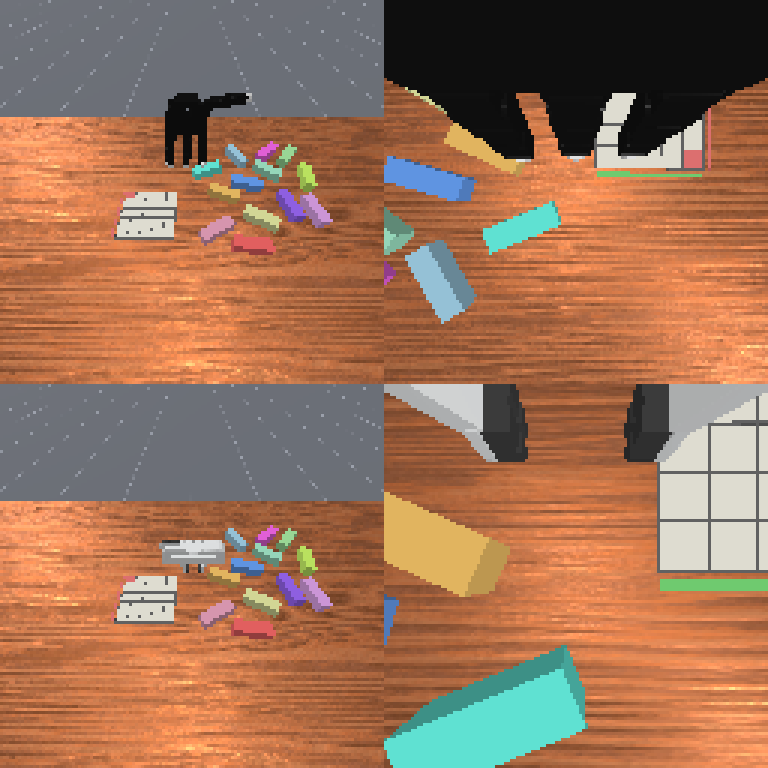

In [3]:
# Cameras side by side: rows = embodiment, columns = fixed workspace camera | palm camera (both 128x128 RGB).
rows = [np.concatenate([frames[n]["base_camera"], frames[n]["palm_camera"]], axis=1) for n in EMBODIMENTS]
grid = np.concatenate(rows, axis=0)
print("row 1:", list(EMBODIMENTS)[0], "| row 2:", list(EMBODIMENTS)[1], "| left: workspace camera, right: palm camera")
display(Image.fromarray(grid).resize((grid.shape[1] * 3, grid.shape[0] * 3), Image.NEAREST))

# Control conventions differ between the two embodiments:
#  - Allegro hand: 22 dims = root_pos(3) + root_rot(3) + 16 finger joints. In the default pd_joint_delta_pos mode
#    every dim is a DELTA target, so a zero action holds still. It starts with the fingers pointing down.
#  - Panda gripper: 7 dims = root_pos(3) + root_rot(3) + gripper(1). The root is DELTA but the gripper is ABSOLUTE:
#    +1 = fully open (4 cm per finger), -1 = closed, 0 = half open (a 3 cm gap, narrower than a block).
#  - Both start 2 cm-jittered unless robot_init_qpos_noise=0. The scripted demos below use pd_joint_pos (absolute).

--- allegro hand (JengaAllegro-v1): action dims 22, 200 steps
  tcp range  x [-0.27, -0.00]  y [-0.26, -0.01]  z [0.40, 0.66] (m); table top is z = 0
  final score 0 / 33 (best 0), total reward 0.0


2026-10-11 18:38:33,073 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


--- panda gripper (JengaGripper-v1): action dims 7, 200 steps
  tcp range  x [-0.30, -0.07]  y [-0.18, 0.00]  z [0.09, 0.44] (m); table top is z = 0
  final score 0 / 33 (best 0), total reward 0.0


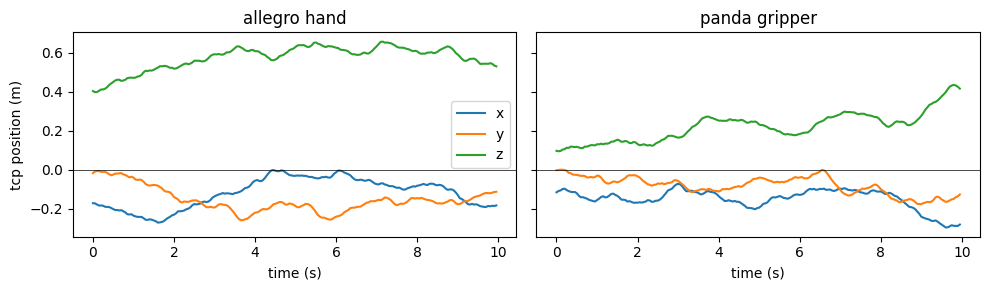

In [4]:
# ---- 2. random-policy rollouts: the same random policy (same seed) on both embodiments ----
STEPS, SEED = 200, 0                      # 200 control steps = 10 s
runs = {}

def side_by_side(ro, size=512):
    """Human-view frame | palm-camera frame (upscaled to the same height) for every step."""
    out = []
    for human, palm in zip(ro.frames, ro.cam_frames):
        palm = np.array(Image.fromarray(palm).resize((size, size), Image.NEAREST))
        out.append(np.concatenate([human, palm], axis=1))
    return out

for name, env_id in EMBODIMENTS.items():
    env = maniskill.make_env(env_id, num_envs=1, render=True, obs_mode="rgbd", sim_backend="physx_cpu")
    policy = policies.RandomPolicy(env, seed=SEED)
    ro = maniskill.rollout(env, policy, STEPS, seed=SEED, camera="palm_camera")
    runs[name] = ro
    lo, hi = ro.tcp.min(0), ro.tcp.max(0)
    print(f"--- {name} ({env_id}): action dims {env.action_space.shape[0]}, {len(ro.frames)} steps")
    print(f"  tcp range  x [{lo[0]:.2f}, {hi[0]:.2f}]  y [{lo[1]:.2f}, {hi[1]:.2f}]  z [{lo[2]:.2f}, {hi[2]:.2f}] (m); table top is z = 0")
    print(f"  final score {ro.scores[-1]:.0f} / {env.unwrapped.evaluate()['max_score'][0].item():.0f} (best {max(ro.scores):.0f}), total reward {sum(ro.rewards):.1f}")
    display(video.show(side_by_side(ro), fps=FPS, width=800))     # left: human view, right: palm camera
    env.close()

fig, ax = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for a, (name, ro) in zip(ax, runs.items()):
    t = np.arange(len(ro.tcp)) / FPS
    for i, axis in enumerate("xyz"): a.plot(t, ro.tcp[:, i], label=axis)
    a.set_title(name); a.set_xlabel("time (s)"); a.axhline(0, color="k", lw=0.5)
ax[0].set_ylabel("tcp position (m)"); ax[0].legend(); plt.tight_layout(); plt.show()

In [5]:
# ---- 3. how reliable are the scripted solvers? Same task, 7 different arrangements of the pile (seeds 0-6) ----
# Only the scatter of the blocks changes with the seed (see JengaDesignEnv._initialize_episode); the design, grid and
# start pose are fixed and the controller is deterministic. A fresh env per seed, so each number is what a fresh run gives
# (the contact-heavy hand build is chaotic: it also depends slightly on what the same env simulated before).
def make_demo_env(env_id, render=False, design=None):
    kw = {} if design is None else dict(design=design)
    return maniskill.make_env(env_id, num_envs=1, render=render, obs_mode="state", control_mode="pd_joint_pos",
                              sim_backend="physx_cpu", max_episode_steps=8000, robot_init_qpos_noise=0.0, **kw)

sweep = {name: [] for name in EMBODIMENTS}
for name, env_id in EMBODIMENTS.items():
    for seed in range(7):
        env = make_demo_env(env_id)
        sweep[name].append(solve_floating(env, seed=seed)["score"])
        env.close()
print(f"{'seed':>14}" + "".join(f"{s:>5d}" for s in range(7)) + f"{'mean':>8}")
for name, scores in sweep.items():
    print(f"{name:>14}" + "".join(f"{s:>5d}" for s in scores) + f"{np.mean(scores):8.1f}   (of 33 cells)")
# The gripper builds the whole design every time. The hand grips a 12 cm block between its thumb and middle finger,
# lets it tilt 10-20 degrees in the grip, and then has to lower it into 4 cm gaps with 1-2 mm tolerance: some seeds
# come out nearly right, others collapse.

2026-10-11 18:40:02,320 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:40:06,687 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:40:11,307 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:40:16,404 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:40:20,927 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:40:25,461 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:40:29,834 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


          seed    0    1    2    3    4    5    6    mean
  allegro hand   28   24   21   27   28   24    8    22.9   (of 33 cells)
 panda gripper   33   33   33   33   33   33   33    33.0   (of 33 cells)


In [6]:
# ---- 4. scripted demonstrations: build the demo design (11 blocks, layers of 5/3/3) with each embodiment ----
# A scripted, privileged-state policy (it reads block poses from the simulator, not images): bottom-up build order,
# grasp each block across its 4 cm side, carry it above the stack, lower it onto its cell, release, retreat.
# See api/jenga_floating_solver.py. Both embodiments get the SAME pile of blocks. DEMO_SEED is the hand's best seed in
# the sweep above (ties -> lowest), so the hand's demo is its best case here, not a typical one.
DEMO_SEED = int(np.argmax(sweep["allegro hand"]))
print(f"demo seed {DEMO_SEED}")
demos = {}
for name, env_id in EMBODIMENTS.items():
    env = make_demo_env(env_id, render=True)
    res, frames_ = solve_and_record(env, seed=DEMO_SEED, every=6, size=384)
    demos[name] = (res, frames_)
    print(f"=== {name} ({env_id}), seed {DEMO_SEED}: {res['score']}/{res['max_score']} cells, success={res['success']}, {res['steps']} control steps ({res['steps'] / FPS:.0f} s)")
    print(format_results(res))
    display(video.show(frames_, fps=FPS, width=640))              # 6x real time (every 6th control step)
    env.close()

demo seed 0


=== allegro hand (JengaAllegro-v1), seed 0: 28/33 cells, success=False, 3628 control steps (181 s)
score 28/33  success=False  steps=3628
  block  4 (k=0, axis=x) actor=3  placed     mode=normal  err=371.9 mm  cells_ok=False
  block  5 (k=0, axis=x) actor=4  placed     mode=normal  err= 13.3 mm  cells_ok=True
  block  1 (k=0, axis=y) actor=0  placed     mode=normal  err=  5.0 mm  cells_ok=True
  block  2 (k=0, axis=y) actor=1  placed     mode=normal  err=  3.9 mm  cells_ok=True
  block  3 (k=0, axis=y) actor=2  placed     mode=normal  err=  4.9 mm  cells_ok=True
  block  6 (k=1, axis=x) actor=5  placed     mode=normal  err=  0.7 mm  cells_ok=True
  block  7 (k=1, axis=x) actor=11  placed     mode=normal  err= 17.1 mm  cells_ok=True
  block  8 (k=1, axis=x) actor=12  placed     mode=normal  err= 21.6 mm  cells_ok=False
  block 10 (k=2, axis=y) actor=9  placed     mode=normal  err= 12.2 mm  cells_ok=True
  block  9 (k=2, axis=y) actor=8  placed     mode=drop  err=  2.7 mm  cells_ok=True


2026-10-11 18:40:54,263 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


=== panda gripper (JengaGripper-v1), seed 0: 33/33 cells, success=True, 2367 control steps (118 s)
score 33/33  success=True  steps=2367
  block  4 (k=0, axis=x) actor=3  placed     mode=normal  err=  0.5 mm  cells_ok=True
  block  5 (k=0, axis=x) actor=4  placed     mode=normal  err=  0.2 mm  cells_ok=True
  block  1 (k=0, axis=y) actor=0  placed     mode=normal  err=  0.5 mm  cells_ok=True
  block  2 (k=0, axis=y) actor=1  placed     mode=normal  err=  0.6 mm  cells_ok=True
  block  3 (k=0, axis=y) actor=2  placed     mode=normal  err=  0.3 mm  cells_ok=True
  block  6 (k=1, axis=x) actor=5  placed     mode=normal  err=  0.1 mm  cells_ok=True
  block  7 (k=1, axis=x) actor=6  placed     mode=normal  err=  1.6 mm  cells_ok=True
  block  8 (k=1, axis=x) actor=7  placed     mode=normal  err=  3.2 mm  cells_ok=True
  block 10 (k=2, axis=y) actor=9  placed     mode=normal  err=  1.2 mm  cells_ok=True
  block  9 (k=2, axis=y) actor=8  placed     mode=drop  err=  1.2 mm  cells_ok=True
  blo

In [7]:
# ---- 5. other layouts: the same solvers on freshly generated random designs ----
# Designs come from api.jenga_designs.random_design (horizontal blocks only: the solvers skip vertical ones) and must pass
# the physics stability check. The pile is seed 0 in every case. Nothing in the solvers is specific to the demo design:
# they read the env's design and the block poses, and derive build order and clearances from the design.
from api.jenga_designs import random_design
from api.jenga import check_stability
from api.jenga_core import design_to_blocks

N_BLOCKS = [8, 10, 9, 11, 8, 10]
layout_scores = {name: [] for name in EMBODIMENTS}
for dseed, n in enumerate(N_BLOCKS):
    design = random_design(n, rng=dseed, allow_vertical=False, stability_fn=lambda d: check_stability(d).stable)
    for name, env_id in EMBODIMENTS.items():
        env = make_demo_env(env_id, design=design.tolist())
        r = solve_floating(env, seed=0)
        layout_scores[name].append(f"{r['score']}/{r['max_score']}")
        env.close()
print(f"{'design (blocks, layers)':>26}" + "".join(f"{n:>16}" for n in EMBODIMENTS))
for i, n in enumerate(N_BLOCKS):
    layers = len({b.layer for b in design_to_blocks(random_design(n, rng=i, allow_vertical=False, stability_fn=lambda d: check_stability(d).stable))})
    print(f"{f'#{i}: {n} blocks, {layers} layers':>26}" + "".join(f"{layout_scores[nm][i]:>16}" for nm in EMBODIMENTS))

2026-10-11 18:41:12,534 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:41:25,715 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:41:38,145 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:41:52,973 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:42:05,162 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


2026-10-11 18:42:18,376 - mani_skill  - WARNING - Mimic targets dictionary is missing for controller config for floating_panda_gripper_cam. Assuming the first joint is the control joint and the second joint is the mimic joint


   design (blocks, layers)    allegro hand   panda gripper
    #0: 8 blocks, 2 layers           17/24           20/24
   #1: 10 blocks, 3 layers           16/30           30/30
    #2: 9 blocks, 3 layers           18/27           27/27
   #3: 11 blocks, 2 layers           26/33           33/33
    #4: 8 blocks, 2 layers           15/24           24/24
   #5: 10 blocks, 3 layers           26/30           28/30
